
SYMMETRY ANALYSIS: 1L MoS2

Main rotational axes:
  C2   ( 180.0 deg) : not found
  C3   ( 120.0 deg) : FOUND
  C4   (  90.0 deg) : not found
  C6   (  60.0 deg) : not found

In-plane C2 axes:
  C2_2 (  30.0 deg) : FOUND
  C2_4 (  90.0 deg) : FOUND
  C2_6 ( 150.0 deg) : FOUND

Mirror operations:
  sigma_h : FOUND
  sigma_2 (  30.0 deg) : FOUND
  sigma_4 (  90.0 deg) : FOUND
  sigma_6 ( 150.0 deg) : FOUND

Inversion:  not found

SYMMETRY ANALYSIS: 10L MoS2

Main rotational axes:
  C2   ( 180.0 deg) : not found
  C3   ( 120.0 deg) : FOUND
  C4   (  90.0 deg) : not found
  C6   (  60.0 deg) : not found

In-plane C2 axes:
  C2_1 (   0.0 deg) : FOUND
  C2_3 (  60.0 deg) : FOUND
  C2_5 ( 120.0 deg) : FOUND

Mirror operations:
  sigma_h : not found
  sigma_2 (  30.0 deg) : FOUND
  sigma_4 (  90.0 deg) : FOUND
  sigma_6 ( 150.0 deg) : FOUND

Inversion:  FOUND

SYMMETRY ANALYSIS: Bulk 2H MoS2

Main rotational axes:
  C2   ( 180.0 deg) : FOUND
  C3   ( 120.0 deg) : FOUND
  C4   (  90.0 deg) : n

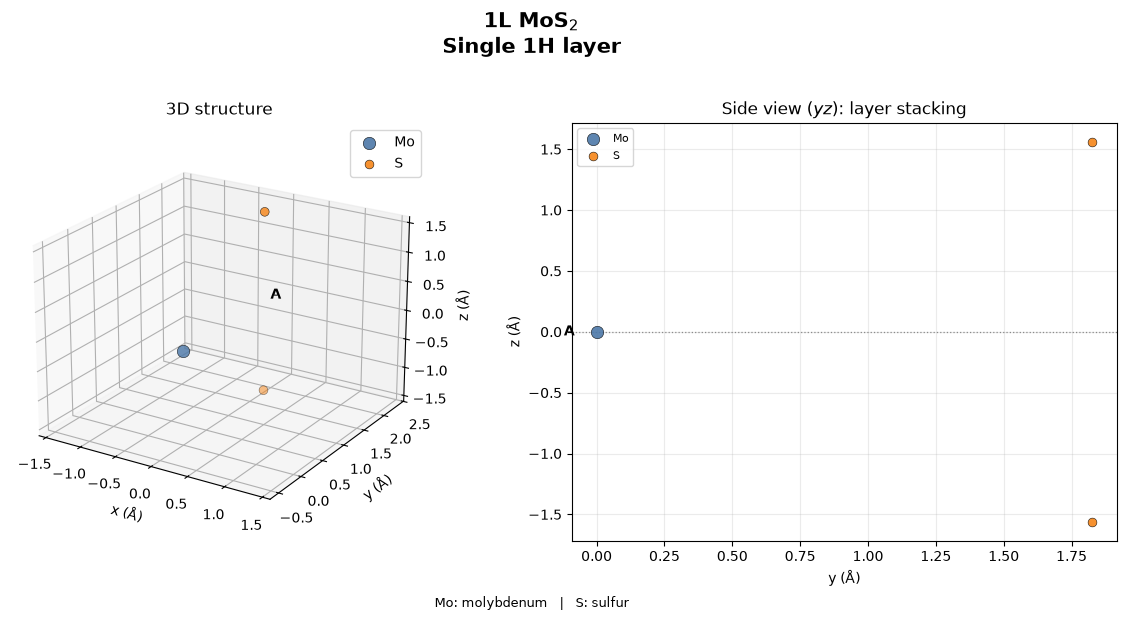

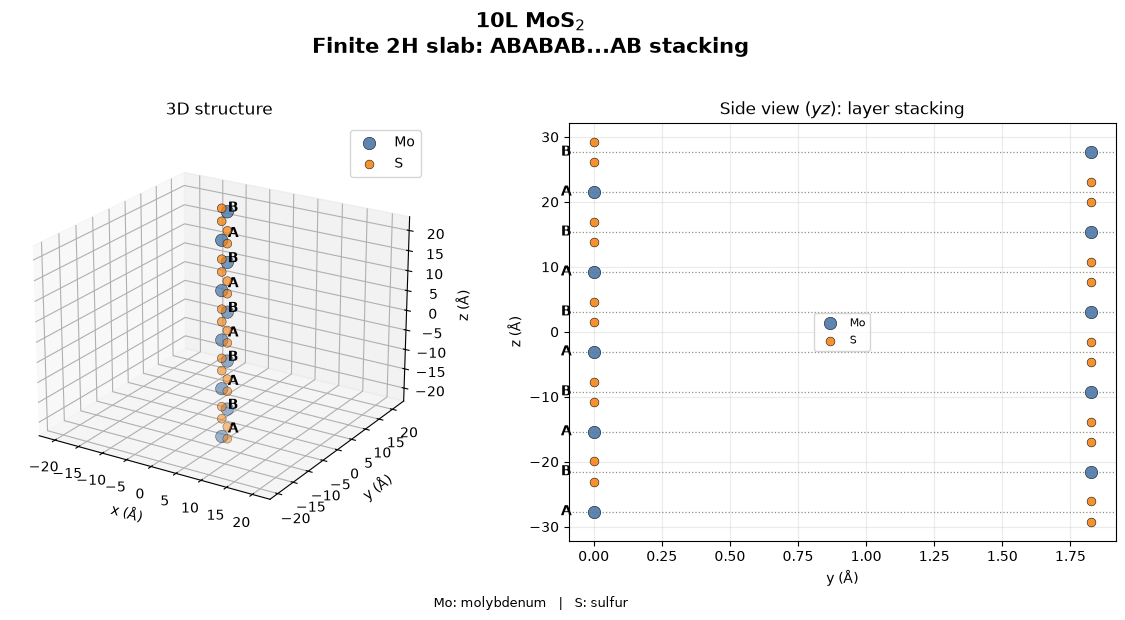

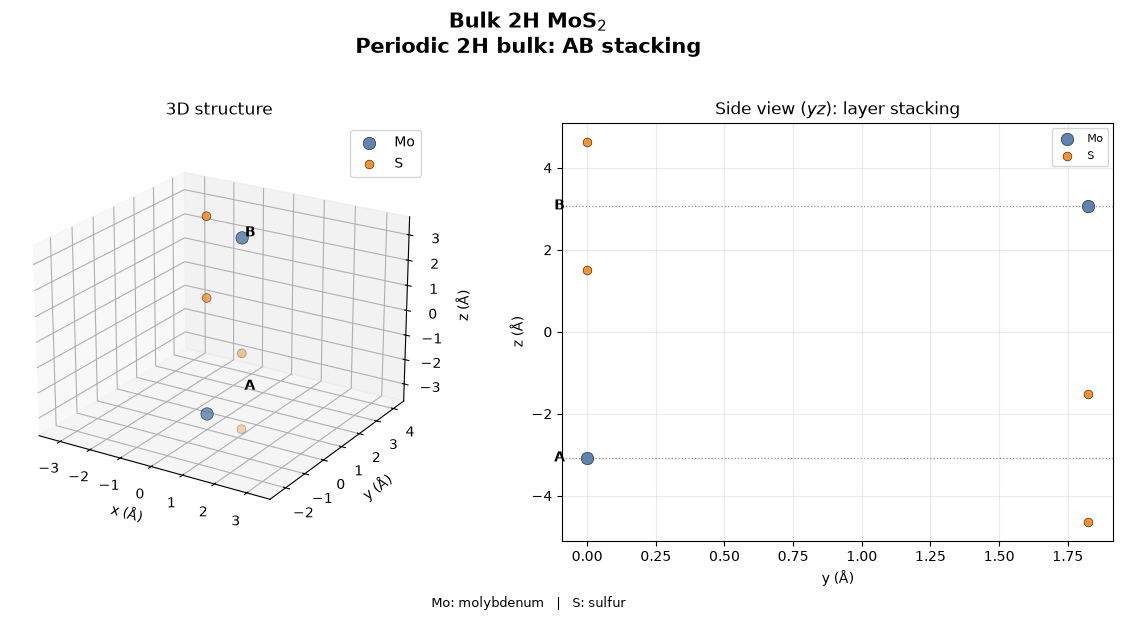

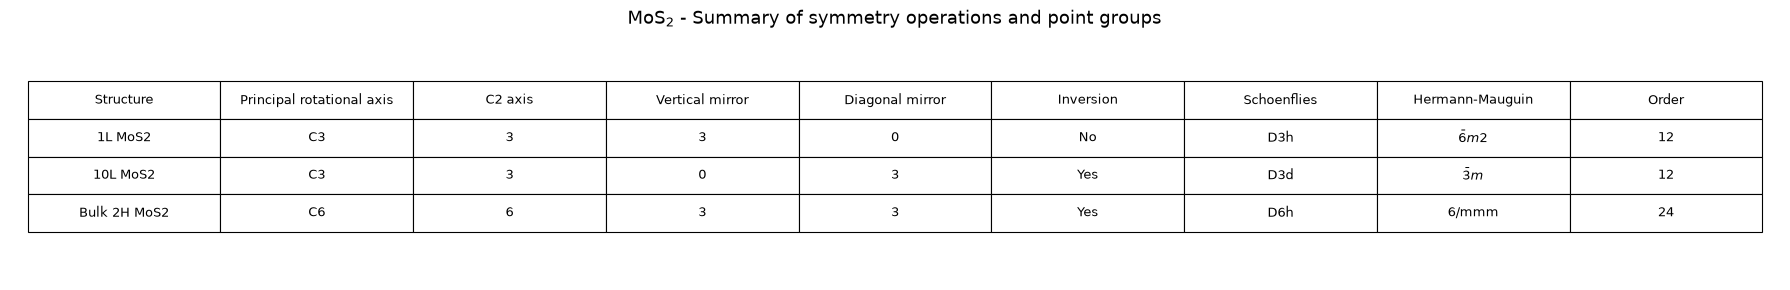

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Cell parameters
a = 3.16               # Å
c = 12.30              # Å, bulk cell 2H

layer_spacing = c / 2  # distance between adjacent planes
S_height = 1.56        # Å, distance S-plane to Mo-plane

TOL = 1e-5
ROUND_DECIMALS = 8

# Definition of 2H stacking

STACK_SHIFT_FRAC = np.array([1.0 / 3.0,2.0 / 3.0])

# Description hexagonal lattice
 
a1 = np.array([ a, 0.0, 0.0 ])

a2 = np.array([ -0.5 * a, np.sqrt(3) / 2.0 * a, 0.0 ])

a3 = np.array([ 0.0, 0.0, c ])

LATTICE_2D = np.column_stack( ( a1[:2], a2[:2] ) )

LATTICE_3D = np.column_stack( ( a1, a2, a3 ) )

LATTICE_2D_INV = np.linalg.inv( LATTICE_2D )

LATTICE_3D_INV = np.linalg.inv( LATTICE_3D )

# Definition geometric operations
# Definition rotation operations
def rotation_z(angle):

    ca = np.cos(angle)
    sa = np.sin(angle)

    return np.array([ [ca, -sa, 0.0], [sa,  ca, 0.0], [0.0, 0.0, 1.0] ])

def rotation_axis( axis, angle ):

    axis = np.asarray( axis, dtype=float )

    axis = axis / np.linalg.norm(axis)

    x, y, z = axis

    K = np.array([ [0.0, -z,   y], [z,    0.0, -x], [-y,   x,  0.0] ])

    I = np.eye(3)

    return ( I * np.cos(angle) + (1.0 - np.cos(angle)) * np.outer(axis, axis) + np.sin(angle) * K )

# Definition mirror operations
    
def mirror_vertical(axis):
    
    axis = np.asarray( axis, dtype=float )

    axis = axis / np.linalg.norm(axis)

    normal = np.array([ -axis[1], axis[0], 0.0 ])

    normal = ( normal / np.linalg.norm(normal) )

    return ( np.eye(3) - 2.0 * np.outer( normal, normal ) )

def mirror_horizontal():

    return np.diag([ 1.0, 1.0, -1.0 ])

# Definition invertion operations

def inversion_matrix():

    return -np.eye(3)

# Definition fractional coordinates. Allow to express the relative position of atoms in respect to the crystalline cell
 
def cart_to_frac_2d(pos):

    return ( LATTICE_2D_INV @ np.asarray(pos[:2]) )

def frac_to_cart_2d(frac):

    frac = np.asarray( frac, dtype=float )

    return ( frac[0] * a1 + frac[1] * a2 )

def cart_to_frac_3d(pos):

    return ( LATTICE_3D_INV @ np.asarray(pos) )

def frac_to_cart_3d(frac):

    return ( LATTICE_3D @ np.asarray(frac) )

# Definition periodic fractional differences. Allow to compare the position considering the equivalent atoms in adjecent cell
 
def periodic_delta_frac_2d( f1, f2 ):

    d = ( np.asarray(f1) - np.asarray(f2) )

    return d - np.round(d)

def periodic_delta_frac_3d( f1, f2 ):

    d = ( np.asarray(f1) - np.asarray(f2) )

    return d - np.round(d)

# Construction single-layer basis 1H-MoS2

def build_single_layer():

    atoms = []
    
    atoms.append( ( "Mo", np.array([ 0.0, 0.0, 0.0 ]) ) )
    
    s_frac = np.array([ 1.0 / 3.0, 2.0 / 3.0])
                      
    s_xy = frac_to_cart_2d( s_frac )

    atoms.append( ( "S", np.array([ s_xy[0], s_xy[1], +S_height ]) ) )
        
    atoms.append( ( "S", np.array([ s_xy[0], s_xy[1], -S_height ]) ) )

    return atoms
 
# Construction SLAB 10-LAYER 2H
 
def build_N_layer(N):

    atoms = []

    basis = build_single_layer()

    stack_shift = frac_to_cart_2d( STACK_SHIFT_FRAC )

    for i in range(N):

        # Layer centered araound z = 0

        z_layer = ( i - (N - 1) / 2.0 ) * layer_spacing

        # A = 0°
        # B = 180°

        angle = ( np.pi if i % 2 == 1 else 0.0 )

        R = rotation_z(angle)

        # Lateral shift

        lateral_shift = np.zeros(3)

        if i % 2 == 1:

            lateral_shift[:2] = ( stack_shift[:2] )

        # Layer construction

        for species, pos in basis:

            new_pos = ( R @ pos + lateral_shift + np.array([ 0.0, 0.0, z_layer ]) )

            atoms.append( ( species, new_pos ) )

    return atoms

# 9. construction BULK 2H
 
def build_bulk():

    atoms = []

    basis = build_single_layer()

    # Relative position of Mo-plane
      
    z_A = -c / 4.0
    z_B = +c / 4.0

    # AB lateral shift
      
    stack_shift = frac_to_cart_2d( STACK_SHIFT_FRAC )

    layer_data = [( 0, z_A, 0.0 ),( 1, z_B, np.pi )]

    for ( layer_index, z_layer, angle ) in layer_data:

        R = rotation_z(angle)

        lateral_shift = np.zeros(3)

        if layer_index == 1:

            lateral_shift[:2] = ( stack_shift[:2] )

        for species, pos in basis:

            new_pos = ( R @ pos + lateral_shift + np.array([ 0.0, 0.0, z_layer ]) )

            atoms.append( ( species, new_pos ) )

    return atoms
 
# Atoms-to-arrays conversion
 
def atoms_to_arrays(atoms):

    species = np.array([ x[0] for x in atoms ])

    positions = np.array([ x[1] for x in atoms ], dtype=float)

    return ( species, positions )
 
# Periodic slab matching. Check if the slab after the symmetry operation is the same as the original

def positions_match_slab( species, positions, transformed_positions, tol=TOL ):

    species = np.asarray( species )

    positions = np.asarray( positions )

    transformed_positions = np.asarray( transformed_positions )

    unique_species = np.unique( species )

    for sp in unique_species:

        idx = np.where( species == sp )[0]

        used = set()

        original_frac = np.array([

            cart_to_frac_2d( positions[i] )

            for i in idx

        ])

        transformed_frac = np.array([

            cart_to_frac_2d( transformed_positions[i] )

            for i in idx

        ])

        for tf, atom_index in zip( transformed_frac, idx ):

            found = False

            for j, original_index in enumerate( idx ):

                if j in used:
                    continue

                dxy = periodic_delta_frac_2d( tf, original_frac[j] )

                dz = ( transformed_positions[ atom_index, 2 ] - positions[ original_index, 2 ] )

                if ( np.linalg.norm(dxy) < tol and abs(dz) < tol ):

                    used.add(j)
                    found = True
                    break

            if not found:
                return False

    return True

# 3D periodic bulk matching. Check if the bulk after the symmetry operation is the same as the original

def positions_match_bulk( species, positions, transformed_positions, tol=TOL ):

    species = np.asarray( species )

    positions = np.asarray( positions )

    transformed_positions = np.asarray( transformed_positions )

    unique_species = np.unique( species )

    for sp in unique_species:

        idx = np.where( species == sp )[0]

        used = set()

        original_frac = np.array([

            cart_to_frac_3d( positions[i] )

            for i in idx

        ])

        transformed_frac = np.array([

            cart_to_frac_3d( transformed_positions[i] )

            for i in idx

        ])

        for tf in transformed_frac:

            found = False

            for j, of in enumerate( original_frac ):

                if j in used:
                    continue

                d = periodic_delta_frac_3d( tf, of )

                if np.linalg.norm(d) < tol:

                    used.add(j)
                    found = True
                    break

            if not found:
                return False

    return True

# Search for XY translation needed to transform one reference atom in an other equivalent atom

def candidate_translations_slab( species, positions, R ):

    reference_index = 0

    ref_species = species[ reference_index ]

    ref_pos = positions[ reference_index ]

    transformed_ref = R @ ref_pos

    candidates = []

    for j, sp in enumerate( species ):

        if sp != ref_species:
            continue

        t = ( positions[j] - transformed_ref )

        t[2] = 0.0

        candidates.append(t)

    unique = []

    for t in candidates:

        if not any( np.linalg.norm(t - u) < TOL for u in unique ):

            unique.append(t)

    return unique
 
# Search for 3D translation needed to transform one reference atom in an other equivalent atom
 
def candidate_translations_bulk( species, positions, R ):

    reference_index = 0

    ref_species = species[ reference_index ]

    ref_pos = positions[ reference_index ]

    transformed_ref = R @ ref_pos

    candidates = []

    for j, sp in enumerate( species ):

        if sp != ref_species:
            continue

        t = ( positions[j] - transformed_ref )

        candidates.append(t)

    unique = []

    for t in candidates:

        if not any( np.linalg.norm(t - u) < TOL for u in unique ):

            unique.append(t)

    return unique

# Symmetry operation test

def test_symmetry_operation( species, positions, R, dimensionality=2, return_translation=False ):

    if dimensionality == 2:

        candidates = ( candidate_translations_slab( species, positions, R ) )

    else:

        candidates = ( candidate_translations_bulk( species, positions, R ) )  

    for t in candidates:

        transformed = np.array([

            R @ p + t

            for p in positions

        ])

        # Slab

        if dimensionality == 2:

            found = positions_match_slab( species, positions, transformed )

        # Bulk

        else:

            found = positions_match_bulk( species, positions, transformed )

        if found:

            if return_translation:

                return ( True, t )

            return True

    if return_translation:

        return ( False, None )

    return False

# Seach principal axes Cn
 
def generate_main_axis_candidates():

    candidates = []

    for n in [ 2, 3, 4, 6 ]:

        angle = ( 2.0 * np.pi / n )

        candidates.append({

            "name":
                f"C{n}",

            "matrix":
                rotation_z(angle),

            "order":
                n
        })

    return candidates

# Search in-plane C2 axes along 0°, 30°, 60°, 90°, 120°, 150° directions

def generate_inplane_C2_candidates():

    candidates = []

    for k in range(6):

        angle = ( k * np.pi / 6.0 )

        axis = np.array([

            np.cos(angle),

            np.sin(angle),

            0.0

        ])

        candidates.append({

            "name":
                f"C2_{k + 1}",

            "matrix":
                rotation_axis( axis, np.pi ),

            "axis":
                axis,

            "angle_deg":
                np.degrees(angle)

        })

    return candidates

# Search mirror
 
def generate_mirror_candidates():

    candidates = []
      
    # Sigma_h
      
    candidates.append({

        "name":
            "sigma_h",

        "matrix":
            mirror_horizontal(),

        "type":
            "horizontal"

    })

    for k in range(6):

        angle = ( k * np.pi / 6.0 )

        axis = np.array([

            np.cos(angle),

            np.sin(angle),

            0.0

        ])

        candidates.append({

            "name":
                f"sigma_{k + 1}",

            "matrix":
                mirror_vertical(axis),

            "axis":
                axis,

            "angle_deg":
                np.degrees(angle),

            "type":
                "vertical"

        })

    return candidates

# Search inversion
 
def test_inversion( species, positions, dimensionality ):

    return test_symmetry_operation(

        species,
        positions,

        inversion_matrix(),

        dimensionality

    )

# Complete analysis
 
def analyze_symmetry( atoms, dimensionality=2, label="" ):

    species, positions = ( atoms_to_arrays(atoms) )

    result = {

        "label":
            label,

        "dimensionality":
            dimensionality,

        "C_orders":
            [],

        "C2_axes":
            [],

        "sigma_h":
            False,

        "sigma_v":
            [],

        "inversion":
            False

    }

    print()
    print("=" * 80)
    print( f"SYMMETRY ANALYSIS: {label}" )
    print("=" * 80)
             
    # MAIN AXIS

    print( "\nMain rotational axes:" )

    for candidate in ( generate_main_axis_candidates() ):

        found = ( test_symmetry_operation(

                species,

                positions,

                candidate["matrix"],

                dimensionality

            )
        )

        angle = ( 360.0 / candidate["order"] )

        if found:

            result["C_orders"].append( candidate["order"] )

            print(

                f"  "
                f"{candidate['name']:4s}"
                f" "
                f"({angle:6.1f} deg)"
                f" : FOUND"

            )

        else:

            print(

                f"  "
                f"{candidate['name']:4s}"
                f" "
                f"({angle:6.1f} deg)"
                f" : not found"

            )

    # C2 in plane

    print( "\nIn-plane C2 axes:" )

    for candidate in ( generate_inplane_C2_candidates() ):

        found = ( test_symmetry_operation(

                species,

                positions,

                candidate["matrix"],

                dimensionality

            )
        )

        if found:

            result["C2_axes"].append({

                "matrix":
                    candidate["matrix"],

                "angle_deg":
                    candidate["angle_deg"]

            })

            print(

                f"  "
                f"{candidate['name']}"
                f" "
                f"({candidate['angle_deg']:6.1f} deg)"
                f" : FOUND"

            )

    if not result["C2_axes"]:

        print( "  none found" )

    # Mirror

    print( "\nMirror operations:" )

    for candidate in ( generate_mirror_candidates() ):

        found = ( test_symmetry_operation(

                species,

                positions,

                candidate["matrix"],

                dimensionality

            )
        )

          # Sigma_h
  
        if ( candidate["type"] == "horizontal" ):

            result["sigma_h"] = found

            print(

                "  sigma_h : "
                +
                ( "FOUND" if found else "not found" )

            )

          # Sigma_v / Sigma_d
  
        elif found:

            result[ "sigma_v" ].append({

                "matrix":
                    candidate["matrix"],

                "angle_deg":
                    candidate["angle_deg"]

            })

            print(

                f"  "
                f"{candidate['name']}"
                f" "
                f"({candidate['angle_deg']:6.1f} deg)"
                f" : FOUND"

            )

    if not result["sigma_v"]:

        print( "  no vertical/dihedral mirrors found" )

    # Inversion

    result["inversion"] = ( test_inversion(

            species,

            positions,

            dimensionality

        )
    )

    print("\nInversion: ", ( "FOUND" if result["inversion"] else "not found" ))

    return result

# Check that all symmetry operation compose a real point group and define the group order

def canonical_matrix_key( M, decimals=ROUND_DECIMALS ):

    A = np.round( np.asarray(M), decimals )

    A[ np.abs(A) < 10 ** (-decimals) ] = 0.0

    return tuple( A.flatten() )

def matrix_group_closure( generators ):

    operations = {}

    identity = np.eye(3)

    operations[ canonical_matrix_key(identity) ] = identity

    for G in generators:

        operations[ canonical_matrix_key(G) ] = G

    changed = True

    while changed:

        changed = False

        current = list( operations.values() )

        for A in current:

            for B in current:

                C = A @ B

                key = ( canonical_matrix_key(C) )

                if key not in operations:

                    operations[key] = C

                    changed = True

    return list( operations.values() )

def collect_found_operations( result ):

    generators = [ np.eye(3) ]
 
    # Principal rotation

    for n in result["C_orders"]:

        generators.append(

            rotation_z( 2.0 * np.pi / n )

        )

    # C2 in-plane
      
    for item in result["C2_axes"]:

        generators.append( item["matrix"] )
      
    # Sigma_h
      
    if result["sigma_h"]:

        generators.append( mirror_horizontal() )
  
    # Sigma_v / Sigma_d
      
    for item in result["sigma_v"]:

        generators.append( item["matrix"] )
      
    # Inversione     

    if result["inversion"]:

        generators.append( inversion_matrix() )

    return generators

def calculate_group_order( result ):

    generators = ( collect_found_operations( result ) )

    group_operations = ( matrix_group_closure( generators ) )

    result["group_order"] = ( len(group_operations) )

    return result[ "group_order" ]

# Definition HERMANN-MAUGUIN nomenclature
 
def hermann_mauguin_from_group( point_group ):

    mapping = {
        
        "D3h":
            r"$\bar{6}m2$",

        "D3d":
            r"$\bar{3}m$",

        "D6h":
            "6/mmm",

        "C6v":
            "6mm",

        "C3v":
            "3m",

        "Ci":
            "-1",

        "Cs":
            "m",

        "C1":
            "1",

        "C2":
            "2",

        "C3":
            "3",

        "C4":
            "4",

        "C6":
            "6"

    }

    return mapping.get( point_group, point_group )

# Point-group identification
 
def deduce_point_group( result ):

    principal_order = (

        max( result["C_orders"] )

        if result["C_orders"]

        else 1

    )

    n_C2 = len( result["C2_axes"] )

    n_sigma = len( result["sigma_v"] )

    sigma_h = result[ "sigma_h" ]

    inversion = result[ "inversion" ]

    group_order = result.get( "group_order", None )

    # D6h

    if (

        principal_order == 6

        and n_C2 >= 6

        and n_sigma >= 6

        and sigma_h

        and inversion

        and group_order == 24

    ):

        return "D6h"

    # D3h

    if (

        principal_order == 3

        and n_C2 >= 3

        and n_sigma >= 3

        and sigma_h

        and not inversion

        and group_order == 12

    ):

        return "D3h"

    # D3d

    if (

        principal_order == 3

        and n_C2 >= 3

        and n_sigma >= 3

        and inversion

        and not sigma_h

        and group_order == 12

    ):

        return "D3d"

    # Assign a simpler point group if it is not the expected one

    if (

        principal_order == 6

        and n_sigma >= 6

        and not inversion

    ):

        return "C6v"

    if (

        principal_order == 3

        and n_sigma >= 3

        and not inversion

        and not sigma_h

    ):

        return "C3v"

    if (

        inversion

        and principal_order == 1

    ):

        return "Ci"

    if (

        sigma_h

        and principal_order == 1

    ):

        return "Cs"

    if principal_order > 1:

        return ( f"C{principal_order}" )

    return "C1"
 
# Operations summary
 
def summarize_operations( result ):

    principal_order = (

        max( result["C_orders"] )

        if result["C_orders"]

        else 1

    )

    return {

        "principal_order":
            principal_order,

        "n_C2":
            len( result["C2_axes"] ),

        "n_sigma_v":
            len( result["sigma_v"] ),

        "sigma_h":
            result["sigma_h"],

        "inversion":
            result["inversion"],

        "group_order":
            result.get( "group_order", None )

    }
        
# Structural visualization

def _set_equal_3d_axes(ax, positions, padding=0.8):

    """Set approximately equal scales on all 3D axes."""

    mins = np.min(positions, axis=0)
    maxs = np.max(positions, axis=0)

    center = 0.5 * (mins + maxs)
    radius = 0.5 * np.max(maxs - mins)
        
    radius = max(radius, 2.0)
    radius *= padding

    ax.set_xlim(center[0] - radius, center[0] + radius)
    ax.set_ylim(center[1] - radius, center[1] + radius)
    ax.set_zlim(center[2] - radius, center[2] + radius)

def plot_structure_report(atoms, title="MoS2", bulk=False):

    species, positions = atoms_to_arrays(atoms)
           
    mo_positions = positions[species == "Mo"]
        
    mo_z = np.sort(mo_positions[:, 2])

    layer_z = []
    for z in mo_z:
        if not layer_z or abs(z - layer_z[-1]) > TOL:
            layer_z.append(z)

    layer_z = np.array(layer_z)

    layer_labels = [ "A" if i % 2 == 0 else "B" for i in range(len(layer_z)) ]

    fig = plt.figure(figsize=(12, 5.8))

    ax3d = fig.add_subplot(1, 2, 1, projection="3d")
    axside = fig.add_subplot(1, 2, 2)

    # 3D view
      
    for sp, color, size in [ ("Mo", "#4C78A8", 80), ("S",  "#F58518", 40), ]:

        idx = np.where(species == sp)[0]
        if len(idx) == 0:
            continue

        ax3d.scatter( positions[idx, 0], positions[idx, 1], positions[idx, 2], s=size, color=color, edgecolors="black", linewidths=0.4, alpha=0.9, label=sp, )

    for i, z in enumerate(layer_z):
        ax3d.text( np.mean(positions[:, 0]), np.max(positions[:, 1]) + 0.15, z, layer_labels[i], fontsize=10, fontweight="bold", )

    ax3d.set_xlabel("x (Å)")
    ax3d.set_ylabel("y (Å)")
    ax3d.set_zlabel("z (Å)")
    ax3d.set_title("3D structure")
    ax3d.legend(loc="upper right", frameon=True)
    _set_equal_3d_axes(ax3d, positions)
    ax3d.view_init(elev=22, azim=-58)

    # Side view: yz plane
      
    for sp, color, size in [ ("Mo", "#4C78A8", 80), ("S",  "#F58518", 40), ]:

        idx = np.where(species == sp)[0]
        if len(idx) == 0:
            continue

        axside.scatter( positions[idx, 1], positions[idx, 2], s=size, color=color, edgecolors="black", linewidths=0.4, alpha=0.9, label=sp, zorder=3, )
           
    for i, z in enumerate(layer_z):
        axside.axhline( z, linestyle=":", linewidth=0.9, color="0.45", alpha=0.8, )
        axside.text( np.min(positions[:, 1]) - 0.08, z, layer_labels[i], fontsize=10, fontweight="bold", va="center", ha="right", )

    axside.set_xlabel("y (Å)")
    axside.set_ylabel("z (Å)")
    axside.set_title("Side view ($yz$): layer stacking")
    axside.grid(True, alpha=0.25)
    axside.legend(loc="best", fontsize=8)

    if len(layer_z) == 1:
        stacking_text = "Single 1H layer"
    elif bulk:
        stacking_text = "Periodic 2H bulk: AB stacking"
    else:
        stacking_text = "Finite 2H slab: ABABAB...AB stacking"

    fig.suptitle( f"{title}\n{stacking_text}", fontsize=15, fontweight="bold", y=1.02, )

    fig.text( 0.5, -0.01, "Mo: molybdenum   |   S: sulfur", ha="center", fontsize=9, )

    plt.tight_layout()
    plt.show()

def vertical_mirror_label( point_group, n_sigma ):

    if point_group == "D3h":

        return ( "3 sigma_v" )

    if point_group == "D3d":

        return ( "3 sigma_d" )

    if point_group == "D6h":

        return ( "3 sigma_v + 3 sigma_d" )

    if n_sigma == 0:

        return "0"

    return str( n_sigma )

 
# Run analysis
# 1L
 
MoS2_1L = build_N_layer(1)

result_1L = analyze_symmetry( MoS2_1L, dimensionality=2, label="1L MoS2" )

calculate_group_order(result_1L)
group_1L = deduce_point_group(result_1L)

# 10L

MoS2_10L = build_N_layer(10)

result_10L = analyze_symmetry( MoS2_10L, dimensionality=2, label="10L MoS2" )

calculate_group_order(result_10L)
group_10L = deduce_point_group(result_10L)

# Bulk
 
MoS2_bulk = build_bulk()

result_bulk = analyze_symmetry( MoS2_bulk, dimensionality=3, label="Bulk 2H MoS2" )

calculate_group_order(result_bulk)
group_bulk = deduce_point_group(result_bulk)

 
# Structural figures
 

plot_structure_report( MoS2_1L, "1L MoS$_2$", bulk=False, )

plot_structure_report( MoS2_10L, "10L MoS$_2$", bulk=False, )

plot_structure_report( MoS2_bulk, "Bulk 2H MoS$_2$", bulk=True, )

# Final symmetry table
 
def plot_final_symmetry_table():

    rows = []

    data = [ (result_1L, group_1L), (result_10L, group_10L), (result_bulk, group_bulk), ]

    for result, point_group in data:

        summary = summarize_operations(result)

        if point_group == "D3h":
            n_sigma_v = "3"
            n_sigma_d = "0"
        elif point_group == "D3d":
            n_sigma_v = "0"
            n_sigma_d = "3"
        elif point_group == "D6h":
            n_sigma_v = "3"
            n_sigma_d = "3"
        else:
            n_sigma_v = "0"
            n_sigma_d = "0"

        rows.append([ result["label"], f"C{summary['principal_order']}", str(summary["n_C2"]), n_sigma_v, n_sigma_d, "Yes" if summary["inversion"] else "No", point_group, hermann_mauguin_from_group(point_group), str(summary["group_order"]), ])

    columns = [ "Structure", "Principal rotational axis", "C2 axis", "Vertical mirror", "Diagonal mirror", "Inversion", "Schoenflies", "Hermann-Mauguin", "Order", ]

    fig, ax = plt.subplots(figsize=(18, 3.0))
    ax.axis("off")

    table = ax.table( cellText=rows, colLabels=columns, cellLoc="center", colLoc="center", loc="center", bbox=[0.01, 0.20, 0.98, 0.62], )

    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    table.scale(1.0, 1.6)

    # Keep the clean black-and-white appearance of the reference table.
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("black")
        cell.set_linewidth(0.8)
        if row == 0:
            cell.set_text_props(weight="normal")

    ax.set_title( "MoS$_2$ - Summary of symmetry operations and point groups", fontsize=13, pad=10, )

    plt.tight_layout()
    plt.show()

plot_final_symmetry_table()
